# Experiment 3: Does a stronger Layer 4 classifier change the conclusion? 

1. **Is there boundary signal in the band for any classifier?** (band AUC on validation and on test)
2. **Does any classifier make the pipeline beat the seed-only control?** (Dice, paired with the control)

Eight runs, declared before any test image is scored:

| Id | Model | Input | Training pixels | Role |
| --- | --- | --- | --- | --- |
| R0 | RBF-SVM | pooled template histograms (7x7) + local intensity | definite pixels | main method (reference) |
| R1 | RBF-SVM | all pooled features (7x7, 31x31, intensity, context) | definite + band pixels | SVM given every feature and the band as training data |
| T1 | gradient boosting | all pooled features | definite pixels | stronger tabular model |
| T2 | gradient boosting | all pooled features | definite + band pixels | same, trained on the band itself |
| T3 | MLP | all pooled features | definite + band pixels | neural tabular model |
| N1 | CNN (receptive field 33 px) | the K template-score maps (Layer 2 output) + ROI | definite pixels | CNN on the granular features |
| N2 | CNN (receptive field 33 px) | the K template-score maps + ROI | definite + band pixels | same, trained on the band itself |
| N3 | CNN (receptive field 33 px) | ROI pixels only (no GrC layers) | definite + band pixels | diagnostic: is there signal in the pixels at all? |

In [ ]:
# Imports and config
!pip install -q opencv-python scikit-learn scipy tqdm joblib

import os, json, random, warnings, math, time, gc, copy, pickle
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm
from numpy.lib.stride_tricks import sliding_window_view
from scipy import ndimage
from scipy.sparse import csr_matrix, diags, identity
from scipy.sparse.linalg import spsolve
from scipy.spatial.distance import cdist
from scipy.ndimage import distance_transform_edt
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
import torch, torch.nn as nn, torch.nn.functional as F
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

DRIVE_ROOT = "/content/drive/MyDrive/cbis_ddsm_grc_project_v3_dicom"      
CONFIG = json.load(open(os.path.join(DRIVE_ROOT, "config.json")))
globals().update(CONFIG)
SEED = CONFIG["SEED"]
random.seed(SEED); np.random.seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

LAP_WINDOW, LAP_EPSILON = 3, 1e-7
MU_GRID = [0.1, 1.0, 10.0]
N_BOOT = 2000                         
N_BOOT_AUC = 200                      
DEF_ROWS, BAND_ROWS = 300, 200        
MAX_FIT, MAX_TUNE_FIT = 20000, 8000   
MAX_FIT_TREE, HGB_ITERS = 300000, 200
HGB_GRID = [(lr, leaf) for lr in (0.05, 0.15) for leaf in (8, 31)]            
MAX_FIT_NN, MLP_ITERS = 150000, 60
MLP_GRID = [(h, a) for h in ((64, 64), (128, 64)) for a in (1e-4, 1e-2)]      
CNN_CH, CNN_DILATIONS = 32, (1, 2, 4, 8, 1)                                   
CNN_EPOCHS, CNN_PATIENCE, CNN_LR, CNN_ACCUM = 24, 6, 2e-3, 8
TEST_AUC_PX = 1000                   
NB7_DIR = os.path.join(RESULTS_DIR, "nb7"); os.makedirs(os.path.join(NB7_DIR, "models"), exist_ok=True)
print("Config loaded. Device:", DEVICE)


Mounted at /content/drive
Config loaded. Device: cuda


## Data and frozen settings

In [ ]:
final_df_loaded = pd.read_csv(os.path.join(RESULTS_DIR, "final_df_loaded.csv"))
raw_arch = np.load(os.path.join(PREPROCESSED_DIR, "raw_crops.npz"))
gt_arch  = np.load(os.path.join(PREPROCESSED_DIR, "gt_masks.npz"))
roi_arch = np.load(os.path.join(PREPROCESSED_DIR, "rois.npz"))
class_of, patient_of = dict(zip(final_df_loaded['image_id'], final_df_loaded['class'])), dict(zip(final_df_loaded['image_id'], final_df_loaded['patient_id']))

sp = json.load(open(os.path.join(RESULTS_DIR, "train_test_split.json")))
train_ids, val_ids, test_ids = set(sp['train_ids']), set(sp['val_ids']), set(sp['test_ids'])
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    for unit in ('lesions', 'patients'):
        assert not (set(sp[f'{a}_{unit}']) & set(sp[f'{b}_{unit}'])), f"{unit} leakage {a}/{b}"

RAW = {i: raw_arch[i].astype(np.float32) for i in raw_arch.files}
GT  = {i: gt_arch[i] for i in gt_arch.files}
usable = set(RAW) & set(GT)
TRAIN_IDS, VAL_IDS = sorted(train_ids & usable), sorted(val_ids & usable)
EVAL_TEST = sorted(test_ids & usable)
assert len(EVAL_TEST) == len(test_ids), "some test images are unusable - a configuration study must use the whole test split"
FINAL_K = json.load(open(os.path.join(MODELS_DIR, "selected_K.json")))['selected_K']
NB4 = json.load(open(os.path.join(RESULTS_DIR, "final_results.json")))
L5_MAIN = NB4['config']['layer5_variant']; L5_PLAIN = L5_MAIN.replace('hybrid', 'plain')
preprocessed_results = {i: {'gt_mask': GT[i], 'class': class_of[i], 'patient_id': patient_of[i]} for i in usable}
print(f"train {len(TRAIN_IDS)} | val {len(VAL_IDS)} | test {len(EVAL_TEST)} images; K = {FINAL_K}; Layer 5 variant = {L5_MAIN}")
print("Every run below is scored on exactly these", len(EVAL_TEST), "test images.")


train 642 | val 156 | test 269 images; K = 8; Layer 5 variant = paper_hybrid_mu1
Every run below is scored on exactly these 269 test images.


## Feature functions (Layers 1-3), SVM probability wrapper

In [ ]:
CHANNELS = [(ps, kind) for ps in PATCH_SIZES for kind in ('lipw', 'lbpw')]; N_CH = len(CHANNELS); WIN = PATCH_SINGLE
ROW_CHUNK = 96

def apply_layer1(roi, patch_size, lambda_val=None):          #
    lam = LAMBDA_VAL if lambda_val is None else lambda_val
    half = patch_size // 2
    padded = np.pad(roi, half, mode='reflect').astype(np.float32)
    patches = sliding_window_view(padded, (patch_size, patch_size))
    lipw = 1.0 / (1.0 + np.exp(-lam * (patches - 0.5))); lipw_map = lipw.mean(axis=(-2, -1)).astype(np.float32)
    centre = patches[:, :, half, half][:, :, None, None]
    centre = np.where(np.abs(centre - 0.5) < 1e-6, centre + 1e-6, centre)
    xor = patches + centre - 2 * patches * centre
    lbpw = 1.0 / (1.0 + np.exp(-lam * (xor - 0.5))); lbpw[:, :, half, half] = 0.0
    lbpw_map = (lbpw.sum(axis=(-2, -1)) / (patch_size * patch_size - 1)).astype(np.float32)
    return lipw_map, lbpw_map

def layer1_stack(roi):
    h, w = roi.shape; out = np.empty((h, w, N_CH), np.float32); c = 0
    for ps in PATCH_SIZES:
        half = ps // 2; padded = np.pad(roi, half, mode='reflect').astype(np.float32)
        for r0 in range(0, h, ROW_CHUNK):
            r1 = min(h, r0 + ROW_CHUNK)
            patches = sliding_window_view(padded[r0:r1 + 2 * half, :], (ps, ps))
            lipw = 1.0 / (1.0 + np.exp(-LAMBDA_VAL * (patches - 0.5)))
            out[r0:r1, :, c] = lipw.mean(axis=(-2, -1))
            centre = patches[:, :, half, half][:, :, None, None]
            centre = np.where(np.abs(centre - 0.5) < 1e-6, centre + 1e-6, centre)
            xor = patches + centre - 2 * patches * centre
            lbpw = 1.0 / (1.0 + np.exp(-LAMBDA_VAL * (xor - 0.5))); lbpw[:, :, half, half] = 0.0
            out[r0:r1, :, c + 1] = lbpw.sum(axis=(-2, -1)) / (ps * ps - 1)
        c += 2
    return out

_t = np.random.default_rng(0).random((61, 73)).astype(np.float32)
_s = layer1_stack(_t)
for _i, ps in enumerate(PATCH_SIZES):
    _l, _b = apply_layer1(_t, ps)
    assert np.abs(_s[:, :, 2 * _i] - _l).max() < 1e-5 and np.abs(_s[:, :, 2 * _i + 1] - _b).max() < 1e-5
print("Chunked Layer 1 matches the Notebook-2 implementation.")

def center_patches(P):
    P = P.reshape(len(P), N_CH, -1); return (P - P.mean(axis=2, keepdims=True)).reshape(len(P), -1)

def layer2_scores(stack_z, templates):
    h, w, C = stack_z.shape; K = len(templates); half = WIN // 2
    Tc = center_patches(templates.reshape(K, -1).astype(np.float32)); Wm = np.sign(Tc); Wm[Wm == 0] = 1.0; Wn = np.linalg.norm(Wm, axis=1)
    padded = np.pad(stack_z, ((half, half), (half, half), (0, 0)), mode='reflect'); out = np.empty((h, w, K), np.float32)
    for r0 in range(0, h, ROW_CHUNK // 2):
        r1 = min(h, r0 + ROW_CHUNK // 2)
        win = sliding_window_view(padded[r0:r1 + 2 * half], (WIN, WIN), axis=(0, 1))
        P = center_patches(win.reshape((r1 - r0) * w, C * WIN * WIN).astype(np.float32))
        sc = ((P @ Wm.T) / (np.linalg.norm(P, axis=1, keepdims=True) * Wn[None, :] + 1e-8) + 1.0) * 0.5
        out[r0:r1] = sc.reshape(r1 - r0, w, K)
    return out

def _odd(w, h, ww):
    w = min(w, min(h, ww)); return w if w % 2 == 1 else w - 1
def box(a, w):
    h, ww = a.shape[:2]; w = _odd(w, h, ww)
    return cv2.boxFilter(a, -1, (w, w), borderType=cv2.BORDER_REFLECT)
def pool(maps_hwk, w):
    k = maps_hwk.shape[2]; out = np.empty_like(maps_hwk, dtype=np.float32)
    for c in range(k): out[:, :, c] = box(maps_hwk[:, :, c], w)
    t = out.sum(axis=2, keepdims=True)
    return np.where(t > 1e-8, out / t, 1.0 / k).astype(np.float32)

BLOCKS = ['hist7', 'hist31', 'int3', 'ctx']
def feature_maps(roi, sm):
    out = {'hist7': pool(sm, 7), 'hist31': pool(sm, 31), 'int3': np.stack([box(roi, s) for s in (5, 9, 15)], axis=2)}
    m = {s: box(roi, s) for s in (5, 9, 15, 31, 63)}; sq = {s: box(roi * roi, s) for s in (5, 9, 15)}
    std = [np.sqrt(np.maximum(sq[s] - m[s] ** 2, 0)) for s in (5, 9, 15)]
    g = cv2.GaussianBlur(roi, (0, 0), 2); gm = np.sqrt(cv2.Sobel(g, cv2.CV_32F, 1, 0) ** 2 + cv2.Sobel(g, cv2.CV_32F, 0, 1) ** 2)
    out['ctx'] = np.stack(std + [m[31], m[63], m[5] - m[31], box(gm, 9)], axis=2).astype(np.float32)
    return out

K3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
def make_trimap_from_mask(mask):                              
    m = (mask > 127).astype(np.uint8)
    tm = np.full(m.shape, 128, np.uint8)
    tm[cv2.dilate(m, K3, iterations=TRIMAP_DILATE_ITERS) == 0] = 0
    tm[cv2.erode(m, K3, iterations=TRIMAP_ERODE_ITERS) == 1] = 255
    if (tm == 255).sum() < 10: tm[m == 1] = 255
    return tm
def _erode_capped(mask, n):
    out = mask.copy()
    for _ in range(n):
        nxt = cv2.erode(out, K3)
        if nxt.sum() == 0: break
        out = nxt
    return out
def make_eval_trimap(gt_u8):                                  
    m = (gt_u8 > 127).astype(np.uint8); tm = np.full(m.shape, 128, np.uint8)
    tm[cv2.dilate(m, K3, iterations=TRIMAP_DILATE_ITERS) == 0] = 0
    tm[_erode_capped(m, TRIMAP_ERODE_ITERS) == 1] = 255
    return tm

def fast_decision(svm, Xs):
    sv, coef, b, g = svm.support_vectors_.astype(np.float32), svm.dual_coef_.astype(np.float32).ravel(), float(svm.intercept_[0]), float(svm._gamma)
    try:
        import torch
        dev = 'cuda' if torch.cuda.is_available() else 'cpu'
        svt, ct = torch.from_numpy(sv).to(dev), torch.from_numpy(coef).to(dev); sq = (svt ** 2).sum(1); out = []
        for i in range(0, len(Xs), 20000):
            xt = torch.from_numpy(np.ascontiguousarray(Xs[i:i + 20000], dtype=np.float32)).to(dev)
            d2 = (xt ** 2).sum(1, keepdim=True) + sq[None, :] - 2 * xt @ svt.T
            out.append((torch.exp(-g * d2.clamp_min(0)) @ ct + b).cpu().numpy())
        return np.concatenate(out)
    except Exception:
        out = []; sq = (sv ** 2).sum(1)
        for i in range(0, len(Xs), 5000):
            x = Xs[i:i + 5000].astype(np.float32); d2 = (x ** 2).sum(1)[:, None] + sq[None, :] - 2 * x @ sv.T
            out.append(np.exp(-g * np.maximum(d2, 0)) @ coef + b)
        return np.concatenate(out)
print("Feature functions ready.")


Chunked Layer 1 matches the Notebook-2 implementation.
Feature functions ready.


In [ ]:
try:
    import torch
    DEV = 'cuda' if torch.cuda.is_available() else 'numpy'
except ImportError:
    torch, DEV = None, 'numpy'

class FastRBFProba:
    def __init__(self, svm, scaler, chunk=4096):
        self.mu, self.sd = scaler.mean_.astype(np.float64), scaler.scale_.astype(np.float64)
        self.sv = svm.support_vectors_.astype(np.float64); self.coef = svm.dual_coef_[0].astype(np.float64)
        self.b, self.gamma = float(svm.intercept_[0]), float(svm._gamma)
        self.A, self.B, self.chunk = float(svm.probA_[0]), float(svm.probB_[0]), chunk
        self.sv_sq = (self.sv ** 2).sum(1)
        self.sv32, self.sq32, self.c32 = self.sv.astype(np.float32), self.sv_sq.astype(np.float32), self.coef.astype(np.float32)
        if DEV != 'numpy':
            self.t_sv, self.t_c, self.t_sq = [torch.tensor(a, dtype=torch.float32, device=DEV) for a in (self.sv, self.coef, self.sv_sq)]
    def decision(self, X):
        out = np.empty(len(X), np.float64)
        for s in range(0, len(X), self.chunk):
            Z = ((X[s:s + self.chunk].astype(np.float64) - self.mu) / self.sd).astype(np.float32)
            if DEV == 'numpy':
                d2 = (Z ** 2).sum(1)[:, None] + self.sq32[None, :] - 2.0 * Z @ self.sv32.T
                np.maximum(d2, 0, out=d2); d2 *= -np.float32(self.gamma); np.exp(d2, out=d2)
                out[s:s + self.chunk] = (d2 @ self.c32).astype(np.float64) + self.b
            else:
                Zt = torch.tensor(Z, device=DEV)
                d2 = (Zt ** 2).sum(1, keepdim=True) + self.t_sq[None, :] - 2.0 * Zt @ self.t_sv.T
                out[s:s + self.chunk] = (torch.exp(-self.gamma * d2.clamp_min(0)) @ self.t_c).double().cpu().numpy() + self.b
        return out
    def proba(self, X):
        return (1.0 / (1.0 + np.exp(self.A * self.decision(X) - self.B))).astype(np.float32)

## Layer 5 and metrics

In [ ]:
def _downscale_trimap(trimap, hs, ws):
    h0, w0 = trimap.shape
    tm_s = cv2.resize(trimap, (ws, hs), interpolation=cv2.INTER_NEAREST)
    fg0 = np.argwhere(trimap == 255)
    if len(fg0) and not (tm_s == 255).any():
        cy, cx = fg0.mean(axis=0)
        tm_s[min(hs - 1, int(cy * hs / h0)), min(ws - 1, int(cx * ws / w0))] = 255
    return tm_s

def build_matting_laplacian(feat, win=LAP_WINDOW, eps=LAP_EPSILON):
    h, w = feat.shape; n = h * w; k = win * win
    idx = np.arange(n).reshape(h, w)
    iw = sliding_window_view(idx, (win, win)).reshape(-1, k)
    fw = sliding_window_view(feat.astype(np.float64), (win, win)).reshape(-1, k)
    mu = fw.mean(axis=1, keepdims=True)
    var = fw.var(axis=1, keepdims=True) + eps / k
    d = fw - mu
    W = (1.0 + d[:, :, None] * d[:, None, :] / var[:, :, None]) / k
    vals = np.eye(k)[None] - W
    rows = np.repeat(iw[:, :, None], k, axis=2).ravel()
    cols = np.repeat(iw[:, None, :], k, axis=1).ravel()
    return csr_matrix((vals.ravel(), (rows, cols)), shape=(n, n))

def _laplacian_loop(feat, win=LAP_WINDOW, eps=LAP_EPSILON):      
    h, w = feat.shape; n = h * w; half = win // 2; idx = np.arange(n).reshape(h, w)
    rows, cols, vals = [], [], []
    for i in range(half, h - half):
        for j in range(half, w - half):
            wi = idx[i-half:i+half+1, j-half:j+half+1].ravel()
            wf = feat[i-half:i+half+1, j-half:j+half+1].ravel().astype(np.float64)
            k = len(wf); var = wf.var() + eps / k; df = (wf - wf.mean()).reshape(-1, 1)
            Wm = (1.0 + (df @ df.T) / var) / k
            for a in range(k):
                for b in range(k):
                    rows.append(wi[a]); cols.append(wi[b]); vals.append((1.0 if a == b else 0.0) - Wm[a, b])
    return csr_matrix((vals, (rows, cols)), shape=(n, n))

_t = np.random.default_rng(0).random((14, 17)).astype(np.float32)
assert abs(build_matting_laplacian(_t) - _laplacian_loop(_t)).max() < 1e-9, "vectorised Laplacian differs from v1"
print("Vectorised Matting Laplacian matches the v1 loop implementation.")

GAMMA = HYBRID_GAMMA                      
def make_variants():
    v = {'legacy_hybrid': dict(lap='prob',  mu=0.0, w_int=0.0, post=GAMMA),
         'legacy_plain' : dict(lap='prob',  mu=0.0, w_int=0.0, post=None)}
    for m in MU_GRID:
        v[f'paper_hybrid_mu{m:g}'] = dict(lap='image', mu=m, w_int=1 - GAMMA, post=None)
        v[f'paper_plain_mu{m:g}']  = dict(lap='image', mu=m, w_int=0.0,       post=None)
    return v
VARIANTS = make_variants()

def _grid_size(shape, max_nodes=MAX_NODES):
    h0, w0 = shape
    s = min(1.0, math.sqrt(max_nodes / float(h0 * w0)))
    return max(8, int(round(h0 * s))), max(8, int(round(w0 * s)))

def solve_alpha(prob_map, trimap, roi, variant, max_nodes=MAX_NODES, lam=LAMBDA_PROPAGATION):
    h0, w0 = prob_map.shape
    hs, ws = _grid_size((h0, w0), max_nodes)
    prob_s = cv2.resize(prob_map, (ws, hs), interpolation=cv2.INTER_LINEAR)
    roi_s  = cv2.resize(roi,      (ws, hs), interpolation=cv2.INTER_LINEAR)
    tm_s   = _downscale_trimap(trimap, hs, ws)
    inten  = roi_s.astype(np.float32); rg = inten.max() - inten.min()
    inten  = (inten - inten.min()) / rg if rg > 1e-8 else np.zeros_like(inten)

    L = build_matting_laplacian(prob_s if variant['lap'] == 'prob' else roi_s)
    known  = ((tm_s == 255) | (tm_s == 0)).ravel().astype(np.float64)
    target = (tm_s == 255).ravel().astype(np.float64)
    A = L + lam * diags(known); b = lam * known * target
    if variant['mu'] > 0:                                             
        a0 = ((1 - variant['w_int']) * prob_s + variant['w_int'] * inten).ravel().astype(np.float64)
        A = A + variant['mu'] * identity(len(a0), format='csr'); b = b + variant['mu'] * a0
    try:
        alpha = spsolve(A.tocsc(), b)
    except Exception as e:
        print(f"  solve failed ({e}); using the probability map"); alpha = prob_s.ravel().astype(np.float64)
    alpha = np.clip(alpha.reshape(hs, ws), 0, 1).astype(np.float32)
    if variant['post'] is not None:                                   
        alpha = np.clip(variant['post'] * alpha + (1 - variant['post']) * inten, 0, 1)
    return cv2.resize(alpha, (w0, h0), interpolation=cv2.INTER_LINEAR).astype(np.float32)

def trimap_only_alpha(trimap, mode='distance'):
    """255 = definite mass, 0 = definite background, 128 = unknown.
    'zero'/'one' fill the band with 0/1; 'distance' interpolates d_bg / (d_fg + d_bg)."""
    fg, bg = trimap == 255, trimap == 0
    alpha = np.zeros(trimap.shape, np.float32); alpha[fg] = 1.0
    unk = ~(fg | bg)
    if mode == 'one':
        alpha[unk] = 1.0
    elif mode == 'distance':
        d_fg, d_bg = distance_transform_edt(~fg), distance_transform_edt(~bg)
        alpha[unk] = (d_bg / np.maximum(d_fg + d_bg, 1e-6))[unk]
    elif mode != 'zero':
        raise ValueError(mode)
    return alpha

def trimap_only_on_grid(trimap, mode='distance', max_nodes=MAX_NODES):
    h0, w0 = trimap.shape; hs, ws = _grid_size((h0, w0), max_nodes)
    a = trimap_only_alpha(_downscale_trimap(trimap, hs, ws), mode)
    return cv2.resize(a, (w0, h0), interpolation=cv2.INTER_LINEAR).astype(np.float32)

print(f"{len(VARIANTS)} Layer 5 variants: {list(VARIANTS)}")

VARIANTS['cf_matting'] = dict(lap='image', mu=0.0, w_int=0.0, post=None)  

Vectorised Matting Laplacian matches the v1 loop implementation.
8 Layer 5 variants: ['legacy_hybrid', 'legacy_plain', 'paper_hybrid_mu0.1', 'paper_plain_mu0.1', 'paper_hybrid_mu1', 'paper_plain_mu1', 'paper_hybrid_mu10', 'paper_plain_mu10']


In [ ]:
def dice(pred, gt):
    s = pred.sum() + gt.sum()
    return float(2 * np.logical_and(pred, gt).sum() / s) if s > 0 else np.nan
def sensitivity(pred, gt):
    tp, fn = np.logical_and(pred, gt).sum(), np.logical_and(~pred, gt).sum()
    return float(tp / (tp + fn)) if (tp + fn) > 0 else np.nan
def specificity(pred, gt):
    tn, fp = np.logical_and(~pred, ~gt).sum(), np.logical_and(pred, ~gt).sum()
    return float(tn / (tn + fp)) if (tn + fp) > 0 else np.nan
def hd95(pred, gt):
    if pred.sum() == 0 or gt.sum() == 0: return np.nan
    pe, ge = pred ^ ndimage.binary_erosion(pred), gt ^ ndimage.binary_erosion(gt)
    pp, gp = np.argwhere(pe), np.argwhere(ge)
    if len(pp) == 0 or len(gp) == 0: return np.nan
    return float(np.percentile(np.concatenate([cdist(pp, gp).min(axis=1), cdist(gp, pp).min(axis=1)]), HD95_PERCENTILE))
def alpha_mae(alpha, gt):
    return float(np.abs(alpha - gt.astype(np.float32)).mean())

def evaluate_alpha_realmask(iid, alpha, thr=ALPHA_THRESHOLD):
    d = preprocessed_results[iid]
    gt = d['gt_mask']
    if gt.shape[:2] != alpha.shape:
        gt = cv2.resize(gt, (alpha.shape[1], alpha.shape[0]), interpolation=cv2.INTER_NEAREST)
    gt = gt > 127; pred = alpha >= thr
    return {'image_id': iid, 'class': d['class'], 'patient_id': d['patient_id'], 'dice': dice(pred, gt),
            'sensitivity': sensitivity(pred, gt), 'specificity': specificity(pred, gt),
            'hd95': hd95(pred, gt), 'alpha_mae': alpha_mae(alpha, gt)}

def eval_many(alphas):
    return pd.DataFrame([evaluate_alpha_realmask(i, a) for i, a in alphas.items()])

def summarise_per_class(df):
    out = []
    for cls in TARGET_CLASSES:
        s = df[df['class'] == cls]
        if len(s):
            out.append({'class': cls, 'n': len(s), 'dice': s['dice'].mean(), 'dice_std': s['dice'].std(),
                        'sensitivity': s['sensitivity'].mean(), 'specificity': s['specificity'].mean(),
                        'hd95': s['hd95'].mean(), 'alpha_mae': s['alpha_mae'].mean()})
    return pd.DataFrame(out)

def paired_bootstrap(df_a, df_b, col='dice', n_boot=N_BOOT, seed=SEED):
    m = df_a[['image_id', 'patient_id', col]].merge(df_b[['image_id', col]], on='image_id', suffixes=('_a', '_b'))
    m['d'] = m[f'{col}_a'] - m[f'{col}_b']; m = m.dropna(subset=['d'])
    g = m.groupby('patient_id')['d'].agg(['sum', 'count'])
    s, c = g['sum'].to_numpy(), g['count'].to_numpy()
    rng = np.random.default_rng(seed)
    ix = rng.integers(0, len(g), size=(n_boot, len(g)))
    boots = s[ix].sum(axis=1) / c[ix].sum(axis=1)
    return float(m['d'].mean()), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5)), len(m)

print("Metrics ready.")

Metrics ready.


## Preprocessing

In [ ]:
def to_u16(a):
    a = a.astype(np.float32); lo, hi = float(a.min()), float(a.max())
    return np.zeros(a.shape, np.uint16) if hi <= lo else ((a - lo) / (hi - lo) * 65535.0).astype(np.uint16)
def multiscale_clahe_u16(img16):
    f = cv2.createCLAHE(clipLimit=CLAHE_CLIP_LIMIT, tileGridSize=tuple(CLAHE_TILE_FINE)).apply(img16)
    c = cv2.createCLAHE(clipLimit=CLAHE_CLIP_LIMIT, tileGridSize=tuple(CLAHE_TILE_COARSE)).apply(img16)
    return (f.astype(np.float32) + c.astype(np.float32)) / 2.0
def normalize01(a):
    a = a.astype(np.float32); lo, hi = a.min(), a.max()
    return (a - lo) / (hi - lo) if hi > lo else np.zeros_like(a)
P0_FN = lambda c: normalize01(multiscale_clahe_u16(to_u16(c)))        

chk = [float(np.abs(P0_FN(RAW[i]) - roi_arch[i]).max()) for i in sorted(usable)[::10]]
print(f"P0 ROI vs stored rois.npz: max abs difference {max(chk):.2e} on {len(chk)} sampled images")
assert max(chk) < 1e-3, "P0 does not reproduce the stored ROIs"

for i in usable: preprocessed_results[i]['trimap_eval'] = make_eval_trimap(GT[i])
base_alphas = {'trimap_distance (same grid)': {i: trimap_only_on_grid(preprocessed_results[i]['trimap_eval'], 'distance') for i in EVAL_TEST},
               'trimap_distance (full res)' : {i: trimap_only_alpha(preprocessed_results[i]['trimap_eval'], 'distance') for i in EVAL_TEST}}
base_df = {k: pd.DataFrame([evaluate_alpha_realmask(i, a) for i, a in v.items()]) for k, v in base_alphas.items()}
BASE = base_df['trimap_distance (same grid)']
print(f"Seed-only control (same grid) on the test split: Dice {BASE['dice'].mean():.4f}  (full res {base_df['trimap_distance (full res)']['dice'].mean():.4f})")

def border_share(ids, reach=16):
    num = den = 0
    for i in ids:
        ev = preprocessed_results[i]['trimap_eval']; h, w = ev.shape; r, c = np.nonzero(ev == 128)
        d = np.minimum.reduce([r, c, h - 1 - r, w - 1 - c]); num += int((d < reach).sum()); den += len(d)
    return num / max(den, 1)
print(f"Share of band pixels within 16 px of the crop border (the CNN sees 16 px on each side): train {border_share(TRAIN_IDS):.3f} | val {border_share(VAL_IDS):.3f} | test {border_share(EVAL_TEST):.3f}")

ALL = list(BLOCKS)                                                    
KINDS = {'def': (0,), 'both': (0, 1)}
RUNS = [
    dict(id='R0', name='R0 SVM, hist7 + int3, definite rows (main)',    family='reference', model='svm', inp=['hist7', 'int3'], rows='def'),
    dict(id='R1', name='R1 SVM, all features, definite + band rows',    family='reference', model='svm', inp=ALL,                rows='both'),
    dict(id='T1', name='T1 gradient boosting, all features, definite',  family='tabular',   model='hgb', inp=ALL,                rows='def'),
    dict(id='T2', name='T2 gradient boosting, all features, def + band', family='tabular',  model='hgb', inp=ALL,                rows='both'),
    dict(id='T3', name='T3 MLP, all features, def + band',              family='tabular',   model='mlp', inp=ALL,                rows='both'),
    dict(id='N1', name='N1 CNN, template maps + ROI, definite',         family='cnn',       model='cnn', inp='grc',              rows='def'),
    dict(id='N2', name='N2 CNN, template maps + ROI, def + band',       family='cnn',       model='cnn', inp='grc',              rows='both'),
    dict(id='N3', name='N3 CNN, ROI pixels only, def + band',           family='cnn (diagnostic)', model='cnn', inp='roi',       rows='both'),
]
RUN_NAMES = [r['name'] for r in RUNS]; MAIN_RUN = RUN_NAMES[0]
assert len(RUNS) == 8
print(f"{len(RUNS)} runs declared:")
for r in RUNS: print("  ", f"[{r['family']}]", r['name'])

P0 ROI vs stored rois.npz: max abs difference 0.00e+00 on 107 sampled images
Seed-only control (same grid) on the test split: Dice 0.8009  (full res 0.8063)
Share of band pixels within 16 px of the crop border (the CNN sees 16 px on each side): train 0.032 | val 0.026 | test 0.044
8 runs declared:
   [reference] R0 SVM, hist7 + int3, definite rows (main)
   [reference] R1 SVM, all features, definite + band rows
   [tabular] T1 gradient boosting, all features, definite
   [tabular] T2 gradient boosting, all features, def + band
   [tabular] T3 MLP, all features, def + band
   [cnn] N1 CNN, template maps + ROI, definite
   [cnn] N2 CNN, template maps + ROI, def + band
   [cnn (diagnostic)] N3 CNN, ROI pixels only, def + band


## Shared build: templates and feature rows (train / validation)

In [ ]:
FIT_TOUCHED = set()

def build_p0():
    ROI = {i: P0_FN(RAW[i]).astype(np.float32) for i in TRAIN_IDS + VAL_IDS}
    STK = {i: layer1_stack(ROI[i]).astype(np.float16) for i in TRAIN_IDS + VAL_IDS}
    n, s, s2 = 0, np.zeros(N_CH), np.zeros(N_CH)
    for iid in TRAIN_IDS:
        st = STK[iid].astype(np.float64).reshape(-1, N_CH); s += st.sum(0); s2 += (st ** 2).sum(0); n += len(st)
    mean = (s / n).astype(np.float32); std = np.sqrt(np.maximum(s2 / n - (s / n) ** 2, 1e-12)).astype(np.float32)
    zf = lambda st: (st.astype(np.float32) - mean[None, None, :]) / std[None, None, :]
    rng, patches, half = np.random.default_rng(SEED), [], WIN // 2
    for iid in TRAIN_IDS:
        FIT_TOUCHED.add(iid); tm = make_trimap_from_mask(GT[iid])
        win = sliding_window_view(np.pad(zf(STK[iid]), ((half, half), (half, half), (0, 0)), mode='reflect'), (WIN, WIN), axis=(0, 1))
        for val in (255, 0):
            pos = np.argwhere(tm == val)
            if len(pos) == 0: continue
            if len(pos) > 200: pos = pos[rng.choice(len(pos), 200, replace=False)]
            patches.append(win[pos[:, 0], pos[:, 1]].reshape(len(pos), -1))
    km = KMeans(n_clusters=FINAL_K, init='k-means++', n_init=5, random_state=SEED).fit(center_patches(np.concatenate(patches).astype(np.float32)))
    templates = km.cluster_centers_.reshape(FINAL_K, N_CH, WIN, WIN).astype(np.float32)

    def rows(ids):
        r = np.random.default_rng(SEED); blocks = {b: [] for b in ALL}; y, kind, grp, pos_all = [], [], [], []
        for iid in sorted(ids):
            FIT_TOUCHED.add(iid); gt = GT[iid]; st_, ev_ = make_trimap_from_mask(gt), preprocessed_results[iid]['trimap_eval']; parts = []
            for kname, cap, ip, op in ((0, DEF_ROWS, np.argwhere(st_ == 255), np.argwhere(st_ == 0)),
                                       (1, BAND_ROWS, np.argwhere((ev_ == 128) & (gt > 127)), np.argwhere((ev_ == 128) & (gt <= 127)))):
                if len(ip) == 0 or len(op) == 0: continue
                k = min(len(ip), len(op), cap)
                for pos, lab in ((ip, 1), (op, 0)):
                    if len(pos) > k: pos = pos[r.choice(len(pos), k, replace=False)]
                    parts.append((pos, lab, kname))
            if not parts: continue
            fm = feature_maps(ROI[iid], layer2_scores(zf(STK[iid]), templates))
            for pos, lab, kname in parts:
                for b in ALL: blocks[b].append(fm[b][pos[:, 0], pos[:, 1]])
                y.append(np.full(len(pos), lab)); kind.append(np.full(len(pos), kname)); grp += [iid] * len(pos); pos_all.append(pos)
        return {'X': {b: np.concatenate(v).astype(np.float32) for b, v in blocks.items()}, 'y': np.concatenate(y), 'kind': np.concatenate(kind),
                'grp': np.array(grp), 'pos': np.concatenate(pos_all).astype(np.int32)}
    return {'mean': mean, 'std': std, 'templates': templates, 'TR': rows(TRAIN_IDS), 'VA': rows(VAL_IDS)}

BUILD_PATH = os.path.join(NB7_DIR, "p0_build.pkl")
if os.path.exists(BUILD_PATH):
    B = pickle.load(open(BUILD_PATH, "rb")); FIT_TOUCHED.update(TRAIN_IDS + VAL_IDS); print("Shared build loaded from", BUILD_PATH)
else:
    t0 = time.time(); B = build_p0(); pickle.dump(B, open(BUILD_PATH, "wb")); print(f"Shared build done in {(time.time() - t0) / 60:.1f} min and saved")
TR, VA = B['TR'], B['VA']
VA_BY_IMG = {g: np.nonzero(VA['grp'] == g)[0] for g in np.unique(VA['grp'])}
print(f"train rows {len(TR['y']):,} (definite {int((TR['kind'] == 0).sum()):,}, band {int((TR['kind'] == 1).sum()):,}) | val rows {len(VA['y']):,} (definite {int((VA['kind'] == 0).sum()):,}, band {int((VA['kind'] == 1).sum()):,})")

VAL_PATS = sorted({patient_of[i] for i in VAL_IDS}); PIDX = {p: k for k, p in enumerate(VAL_PATS)}
_brng = np.random.default_rng(SEED + 1); BS_AUC = [_brng.integers(0, len(VAL_PATS), len(VAL_PATS)) for _ in range(N_BOOT_AUC)]
def band_auc_ci(y, dec, grp):
    pid = np.array([PIDX[patient_of[g]] for g in grp]); order = np.argsort(pid, kind='stable')
    sp_ = np.searchsorted(pid[order], np.arange(len(VAL_PATS) + 1)); by = [order[sp_[k]:sp_[k + 1]] for k in range(len(VAL_PATS))]
    out = []
    for b in BS_AUC:
        idx = np.concatenate([by[k] for k in b]); yy = y[idx]
        if 0 < yy.sum() < len(yy): out.append(roc_auc_score(yy, dec[idx]))
    return float(np.percentile(out, 2.5)), float(np.percentile(out, 97.5))

def val_diag(scores, extra):
    k0, k1 = VA['kind'] == 0, VA['kind'] == 1
    lo, hi = band_auc_ci(VA['y'][k1], scores[k1], VA['grp'][k1])
    d = {'val_seed_auc': float(roc_auc_score(VA['y'][k0], scores[k0])), 'val_band_auc': float(roc_auc_score(VA['y'][k1], scores[k1])),
         'val_band_auc_lo': lo, 'val_band_auc_hi': hi}; d.update(extra); return d
print("Shared build ready.")

Shared build done in 2.4 min and saved
train rows 438,578 (definite 219,930, band 218,648) | val rows 110,630 (definite 57,102, band 53,528)
Shared build ready.


## The classifiers (SVM, gradient boosting, MLP, CNN)

In [ ]:
class TabModel:
    def __init__(self, kind, blocks, est, sc=None, use_fast=False):
        self.kind, self.blocks, self.est, self.sc, self.use_fast = kind, blocks, est, sc, use_fast
        self.fast = FastRBFProba(est, sc) if kind == 'svm' else None
    def _cat(self, blocks): return np.concatenate([blocks[b] for b in self.blocks], axis=1)
    def rows_scores(self, D):
        X = self._cat(D['X'])
        return self.fast.decision(X) if self.kind == 'svm' else self.est.predict_proba(X)[:, 1]
    def prob_map(self, inp):
        h, w = inp['roi'].shape; X = np.concatenate([inp['fm'][b].reshape(h * w, -1) for b in self.blocks], axis=1)
        if self.kind == 'svm' and self.use_fast: p = self.fast.proba(X)
        elif self.kind == 'svm': p = np.concatenate([self.est.predict_proba(self.sc.transform(X[s:s + 20000]))[:, 1] for s in range(0, len(X), 20000)])
        else: p = np.concatenate([self.est.predict_proba(X[s:s + 50000])[:, 1] for s in range(0, len(X), 50000)])
        return p.reshape(h, w).astype(np.float32)

def fit_svm(run):
    blocks, kinds = run['inp'], KINDS[run['rows']]
    cat = lambda D: np.concatenate([D['X'][b] for b in blocks], axis=1)
    Xtr_all, Xva_all = cat(TR), cat(VA); mt, mv = np.isin(TR['kind'], kinds), np.isin(VA['kind'], kinds)
    sc = StandardScaler().fit(Xtr_all[mt]); Xtr, ytr = sc.transform(Xtr_all[mt]), TR['y'][mt]; Xva, yva = sc.transform(Xva_all[mv]), VA['y'][mv]
    rng = np.random.default_rng(SEED); gi = rng.choice(len(Xtr), min(MAX_TUNE_FIT, len(Xtr)), replace=False); best = (-1, None, None)
    for C in SVM_C_VALUES:
        for g in SVM_GAMMA_VALUES:
            m = SVC(kernel='rbf', C=C, gamma=g, class_weight='balanced', random_state=SEED).fit(Xtr[gi], ytr[gi])
            s = balanced_accuracy_score(yva, m.predict(Xva))
            if s > best[0] + 1e-12: best = (s, C, g)
    fi = rng.choice(len(Xtr), min(MAX_FIT, len(Xtr)), replace=False)
    svm = SVC(kernel='rbf', C=best[1], gamma=best[2], class_weight='balanced', probability=True, random_state=SEED).fit(Xtr[fi], ytr[fi])
    fast = FastRBFProba(svm, sc); xs = Xva_all[::max(1, len(Xva_all) // 2000)][:2000]
    err = float(np.abs(fast.proba(xs) - svm.predict_proba(sc.transform(xs))[:, 1]).max())
    model = TabModel('svm', blocks, svm, sc, use_fast=err <= 0.01)
    return model, val_diag(model.rows_scores(VA), {'val_bal_acc': float(best[0]), 'params': f"C={best[1]}, gamma={best[2]}", 'fast_err': err, 'train_rows': int(mt.sum())})

def fit_grid(run, make, grid, max_fit, label):
    blocks, kinds = run['inp'], KINDS[run['rows']]
    cat = lambda D: np.concatenate([D['X'][b] for b in blocks], axis=1)
    mt, mv = np.isin(TR['kind'], kinds), np.isin(VA['kind'], kinds)
    Xtr, ytr = cat(TR)[mt], TR['y'][mt]; Xva, yva = cat(VA)[mv], VA['y'][mv]
    rng = np.random.default_rng(SEED); gi = rng.choice(len(Xtr), min(max_fit, len(Xtr)), replace=False); best = (-1, None, None)
    for pt in grid:
        m = make(*pt).fit(Xtr[gi], ytr[gi]); s = balanced_accuracy_score(yva, m.predict(Xva))
        print(f"    {label} {pt}: val balanced accuracy {s:.4f}")
        if s > best[0] + 1e-12: best = (s, pt, m)
    model = TabModel(run['model'], blocks, best[2])
    return model, val_diag(model.rows_scores(VA), {'val_bal_acc': float(best[0]), 'params': str(best[1]), 'train_rows': int(min(max_fit, mt.sum()))})

make_hgb = lambda lr, leaf: HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaf, max_iter=HGB_ITERS, l2_regularization=1.0, random_state=SEED)
make_mlp = lambda h, a: make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=h, alpha=a, early_stopping=True, n_iter_no_change=5, max_iter=MLP_ITERS, random_state=SEED))

class PixelCNN(nn.Module):
    def __init__(self, cin, ch=CNN_CH, dil=CNN_DILATIONS):
        super().__init__(); layers, c = [], cin
        for d in dil: layers += [nn.Conv2d(c, ch, 3, padding=d, dilation=d, padding_mode='replicate'), nn.GroupNorm(8, ch), nn.ReLU(inplace=True)]; c = ch
        layers.append(nn.Conv2d(ch, 1, 1)); self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

CH_SETS = {'grc': list(range(FINAL_K + 1)), 'roi': [FINAL_K]}        
CNN_X, CNN_YD, CNN_YB = {}, {}, {}
def build_cnn_data():
    for iid in TRAIN_IDS + VAL_IDS:
        roi = P0_FN(RAW[iid]).astype(np.float32)
        stz = (layer1_stack(roi) - B['mean'][None, None, :]) / B['std'][None, None, :]
        sm = layer2_scores(stz, B['templates'])
        CNN_X[iid] = np.concatenate([sm, roi[:, :, None]], axis=2).transpose(2, 0, 1).astype(np.float16)
        tm = make_trimap_from_mask(GT[iid]); ev = preprocessed_results[iid]['trimap_eval']; inside = GT[iid] > 127; band = ev == 128
        yd = np.full(tm.shape, -1, np.int8); yd[tm == 255] = 1; yd[tm == 0] = 0
        yb = np.full(tm.shape, -1, np.int8); yb[band & inside] = 1; yb[band & ~inside] = 0
        CNN_YD[iid], CNN_YB[iid] = yd, yb

def pixel_loss(logit, yd, yb, use_band):
    terms = []
    for y, on in ((yd, True), (yb, use_band)):
        if not on: continue
        m = y >= 0
        if int(m.sum()) == 0: continue
        t = y[m].float(); l = F.binary_cross_entropy_with_logits(logit[m], t, reduction='none'); pos = t > 0.5
        w = torch.where(pos, 0.5 / pos.sum().clamp(min=1), 0.5 / (~pos).sum().clamp(min=1))
        terms.append((l * w).sum())
    return sum(terms) / len(terms) if terms else None

class CNNModel:
    kind = 'cnn'
    def __init__(self, net, chs, mu, sd): self.net, self.chs, self.mu, self.sd = net.eval(), chs, mu, sd
    def _x(self, arr): return torch.from_numpy((arr[self.chs].astype(np.float32) - self.mu[:, None, None]) / self.sd[:, None, None]).to(DEVICE)
    def prob_map(self, inp):
        x = np.concatenate([inp['sm'].transpose(2, 0, 1), inp['roi'][None]], axis=0)
        with torch.no_grad(): return torch.sigmoid(self.net(self._x(x)[None])[0, 0]).cpu().numpy().astype(np.float32)
    def rows_scores(self, D):
        assert D is VA; sc = np.zeros(len(VA['y']), np.float32)
        with torch.no_grad():
            for iid, ix in VA_BY_IMG.items():
                p = torch.sigmoid(self.net(self._x(CNN_X[iid])[None])[0, 0]).cpu().numpy(); sc[ix] = p[VA['pos'][ix, 0], VA['pos'][ix, 1]]
        return sc

def fit_cnn(run):
    chs, kinds, use_band = CH_SETS[run['inp']], KINDS[run['rows']], run['rows'] == 'both'
    if not CNN_X: build_cnn_data()
    torch.manual_seed(SEED); rng = np.random.default_rng(SEED)
    s = np.zeros(len(chs)); s2 = np.zeros(len(chs)); cnt = 0
    for iid in TRAIN_IDS:
        a = CNN_X[iid][chs].astype(np.float64).reshape(len(chs), -1); s += a.sum(1); s2 += (a ** 2).sum(1); cnt += a.shape[1]
    mu = (s / cnt).astype(np.float32); sd = (np.sqrt(np.maximum(s2 / cnt - (s / cnt) ** 2, 1e-12)) + 1e-6).astype(np.float32)
    net = PixelCNN(len(chs)).to(DEVICE); opt = torch.optim.Adam(net.parameters(), lr=CNN_LR, weight_decay=1e-5)
    tool = CNNModel(net, chs, mu, sd); mv = np.isin(VA['kind'], kinds); k1 = VA['kind'] == 1
    best, bad, t0 = (-1.0, None, -1), 0, time.time()
    for ep in range(CNN_EPOCHS):
        net.train(); tot, n_img, pending = 0.0, 0, 0; opt.zero_grad()
        for iid in rng.permutation(TRAIN_IDS):
            FIT_TOUCHED.add(iid)
            x = tool._x(CNN_X[iid]); yd = torch.from_numpy(CNN_YD[iid]).to(DEVICE); yb = torch.from_numpy(CNN_YB[iid]).to(DEVICE)
            if rng.random() < 0.5: x, yd, yb = x.flip(-1), yd.flip(-1), yb.flip(-1)
            if rng.random() < 0.5: x, yd, yb = x.flip(-2), yd.flip(-2), yb.flip(-2)
            loss = pixel_loss(net(x[None])[0, 0], yd, yb, use_band)
            if loss is None: continue
            (loss / CNN_ACCUM).backward(); tot += float(loss); n_img += 1; pending += 1
            if pending == CNN_ACCUM: opt.step(); opt.zero_grad(); pending = 0
        if pending: opt.step(); opt.zero_grad()
        net.eval(); sc = tool.rows_scores(VA); bal = balanced_accuracy_score(VA['y'][mv], sc[mv] > 0.5); bauc = roc_auc_score(VA['y'][k1], sc[k1])
        print(f"    epoch {ep + 1:2d}: train loss {tot / max(n_img, 1):.4f} | val balanced accuracy {bal:.4f} | val band AUC {bauc:.3f} | {(time.time() - t0) / 60:.1f} min")
        if bal > best[0] + 1e-9: best, bad = (bal, copy.deepcopy(net.state_dict()), ep + 1), 0
        else:
            bad += 1
            if bad >= CNN_PATIENCE: break
    net.load_state_dict(best[1]); net.eval(); tool = CNNModel(net, chs, mu, sd)
    return tool, val_diag(tool.rows_scores(VA), {'val_bal_acc': float(best[0]), 'params': f"epoch {best[2]} of {CNN_EPOCHS}", 'train_rows': -1})

def model_path(run): return os.path.join(NB7_DIR, "models", f"{run['id']}.pkl")
def save_model(run, model, diag):
    if model.kind == 'cnn':
        torch.save({'state': {k: v.cpu() for k, v in model.net.state_dict().items()}, 'chs': model.chs, 'mu': model.mu, 'sd': model.sd, 'diag': diag}, model_path(run).replace('.pkl', '.pt'))
    else:
        pickle.dump({'kind': model.kind, 'blocks': model.blocks, 'est': model.est, 'sc': model.sc, 'use_fast': model.use_fast, 'diag': diag}, open(model_path(run), 'wb'))
def load_model(run):
    if run['model'] == 'cnn':
        p = model_path(run).replace('.pkl', '.pt')
        if not os.path.exists(p): return None
        d = torch.load(p, map_location='cpu', weights_only=False); net = PixelCNN(len(d['chs'])); net.load_state_dict(d['state']); net.to(DEVICE)
        return CNNModel(net, d['chs'], d['mu'], d['sd']), d['diag']
    if not os.path.exists(model_path(run)): return None
    d = pickle.load(open(model_path(run), 'rb')); return TabModel(d['kind'], d['blocks'], d['est'], d['sc'], d['use_fast']), d['diag']

def get_model(run):
    got = load_model(run)
    if got is not None:
        FIT_TOUCHED.update(TRAIN_IDS + VAL_IDS); return got
    t0 = time.time()
    if run['model'] == 'svm': model, diag = fit_svm(run)
    elif run['model'] == 'hgb': model, diag = fit_grid(run, make_hgb, HGB_GRID, MAX_FIT_TREE, 'boosting')
    elif run['model'] == 'mlp': model, diag = fit_grid(run, make_mlp, MLP_GRID, MAX_FIT_NN, 'MLP')
    else: model, diag = fit_cnn(run)
    diag['minutes_fit'] = (time.time() - t0) / 60; save_model(run, model, diag); return model, diag
print("Models ready.")

Models ready.


In [ ]:
# Builds the CNN inputs once and checks one forward / loss / backward pass.
build_cnn_data()
iid = TRAIN_IDS[0]; x = torch.from_numpy(CNN_X[iid].astype(np.float32)).to(DEVICE)
for variant in ('grc', 'roi'):
    net = PixelCNN(len(CH_SETS[variant])).to(DEVICE); out = net(x[CH_SETS[variant]][None])
    assert out.shape == (1, 1) + tuple(CNN_X[iid].shape[1:]), out.shape
    loss = pixel_loss(out[0, 0], torch.from_numpy(CNN_YD[iid]).to(DEVICE), torch.from_numpy(CNN_YB[iid]).to(DEVICE), True); loss.backward()
    print(f"{variant}: input {tuple(x[CH_SETS[variant]].shape)} -> output {tuple(out.shape)}, loss {float(loss):.4f}, receptive field {1 + 2 * sum(CNN_DILATIONS)} px, parameters {sum(p.numel() for p in net.parameters()):,}")
print(f"CNN inputs built for {len(CNN_X)} train/validation images; device {DEVICE}. Smoke test passed.")

grc: input (9, 131, 134) -> output (1, 1, 131, 134), loss 0.7033, receptive field 33 px, parameters 39,969
roi: input (1, 131, 134) -> output (1, 1, 131, 134), loss 0.7063, receptive field 33 px, parameters 37,665
CNN inputs built for 798 train/validation images; device cuda. Smoke test passed.


In [ ]:
# PART A - fit every declared run on TRAIN, tune on VALIDATION, report validation AUC. 
MODELS, DIAGS = {}, {}
for run in RUNS:
    print(f"[{run['id']}] {run['name']}")
    MODELS[run['id']], DIAGS[run['id']] = get_model(run)
    d = DIAGS[run['id']]
    print(f"    -> val balanced acc {d['val_bal_acc']:.4f} | val seed AUC {d['val_seed_auc']:.3f} | val band AUC {d['val_band_auc']:.3f} [{d['val_band_auc_lo']:.3f}, {d['val_band_auc_hi']:.3f}] | {d['params']} | {d.get('minutes_fit', float('nan')):.1f} min")
VT = pd.DataFrame([{'Run': r['name'], 'Val balanced acc': DIAGS[r['id']]['val_bal_acc'], 'Val seed AUC': DIAGS[r['id']]['val_seed_auc'],
                    'Val band AUC': DIAGS[r['id']]['val_band_auc'], 'CI low': DIAGS[r['id']]['val_band_auc_lo'], 'CI high': DIAGS[r['id']]['val_band_auc_hi']} for r in RUNS])
print(""); print("VALIDATION SUMMARY (context only; test scoring below is fixed and covers all eight runs)")
print(VT.round(3).to_string(index=False))

[R0] R0 SVM, hist7 + int3, definite rows (main)
    -> val balanced acc 0.5431 | val seed AUC 0.562 | val band AUC 0.502 [0.488, 0.516] | C=0.1, gamma=scale | 4.3 min
[R1] R1 SVM, all features, definite + band rows
    -> val balanced acc 0.5439 | val seed AUC 0.630 | val band AUC 0.506 [0.494, 0.520] | C=0.1, gamma=scale | 8.1 min
[T1] T1 gradient boosting, all features, definite
    boosting (0.05, 8): val balanced accuracy 0.6161
    boosting (0.05, 31): val balanced accuracy 0.6128
    boosting (0.15, 8): val balanced accuracy 0.6143
    boosting (0.15, 31): val balanced accuracy 0.6077
    -> val balanced acc 0.6161 | val seed AUC 0.651 | val band AUC 0.516 [0.504, 0.530] | (0.05, 8) | 0.5 min
[T2] T2 gradient boosting, all features, def + band
    boosting (0.05, 8): val balanced accuracy 0.5651
    boosting (0.05, 31): val balanced accuracy 0.5630
    boosting (0.15, 8): val balanced accuracy 0.5630
    boosting (0.15, 31): val balanced accuracy 0.5587
    -> val balanced acc 0.

## Part B - score the test split once per run 

In [ ]:
def test_inputs(iid, need_fm):
    roi = P0_FN(RAW[iid]).astype(np.float32)
    stz = (layer1_stack(roi) - B['mean'][None, None, :]) / B['std'][None, None, :]
    sm = layer2_scores(stz, B['templates']); inp = {'roi': roi, 'sm': sm}
    if need_fm: inp['fm'] = feature_maps(roi, sm)
    return inp

TEST_BAND, _r = {}, np.random.default_rng(SEED + 7)
for iid in EVAL_TEST:
    ev, gt = preprocessed_results[iid]['trimap_eval'], GT[iid] > 127; rr, cc, yy = [], [], []
    for lab, m in ((1, (ev == 128) & gt), (0, (ev == 128) & ~gt)):
        pos = np.argwhere(m)
        if len(pos) > TEST_AUC_PX: pos = pos[_r.choice(len(pos), TEST_AUC_PX, replace=False)]
        rr.append(pos[:, 0]); cc.append(pos[:, 1]); yy.append(np.full(len(pos), lab))
    TEST_BAND[iid] = (np.concatenate(rr), np.concatenate(cc), np.concatenate(yy))

def pooled_auc_ci(y, p, pat, n_boot=N_BOOT_AUC):
    pats = np.unique(pat); inv = np.searchsorted(pats, pat); order = np.argsort(inv, kind='stable')
    sp_ = np.searchsorted(inv[order], np.arange(len(pats) + 1)); by = [order[sp_[k]:sp_[k + 1]] for k in range(len(pats))]
    rng, out = np.random.default_rng(SEED + 2), []
    for _ in range(n_boot):
        idx = np.concatenate([by[k] for k in rng.integers(0, len(pats), len(pats))]); yy = y[idx]
        if 0 < yy.sum() < len(yy): out.append(roc_auc_score(yy, p[idx]))
    return float(roc_auc_score(y, p)), float(np.percentile(out, 2.5)), float(np.percentile(out, 97.5))

def mean_ci(df, col, n_boot=N_BOOT, seed=SEED):
    m = df[['patient_id', col]].dropna(); g = m.groupby('patient_id')[col].agg(['sum', 'count']); s, c = g['sum'].to_numpy(), g['count'].to_numpy()
    ix = np.random.default_rng(seed).integers(0, len(g), size=(n_boot, len(g))); b = s[ix].sum(axis=1) / c[ix].sum(axis=1)
    return float(m[col].mean()), float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))

def score_run(run, model, diag):
    t0 = time.time(); alphas, ys, ps, pats, img_auc = {}, [], [], [], {}
    for iid in tqdm(EVAL_TEST, desc=f"test {run['id']}", leave=False):
        inp = test_inputs(iid, need_fm=model.kind != 'cnn'); pm = model.prob_map(inp)
        alphas[iid] = solve_alpha(pm, preprocessed_results[iid]['trimap_eval'], inp['roi'], VARIANTS[L5_MAIN])
        r, c, y = TEST_BAND[iid]; p = pm[r, c]; ys.append(y); ps.append(p); pats += [patient_of[iid]] * len(y)
        img_auc[iid] = float(roc_auc_score(y, p)) if 0 < y.sum() < len(y) else np.nan
    df = pd.DataFrame([evaluate_alpha_realmask(i, a) for i, a in alphas.items()]); df.insert(0, 'run', run['name']); df['band_auc_img'] = df['image_id'].map(img_auc)
    a, lo, hi = pooled_auc_ci(np.concatenate(ys), np.concatenate(ps), np.array(pats)); am, alo, ahi = mean_ci(df, 'band_auc_img')
    meta = dict(diag); meta.update(id=run['id'], run=run['name'], family=run['family'], model=run['model'], train_rows_kind=run['rows'], K=int(FINAL_K), layer5=L5_MAIN,
                test_band_auc=a, test_band_auc_lo=lo, test_band_auc_hi=hi, test_band_auc_img=am, test_band_auc_img_lo=alo, test_band_auc_img_hi=ahi,
                minutes_test=(time.time() - t0) / 60, fit_touched=sorted(FIT_TOUCHED), test_ids=sorted(df['image_id']))
    df.to_csv(os.path.join(NB7_DIR, f"per_image_{run['id']}.csv"), index=False); json.dump(meta, open(os.path.join(NB7_DIR, f"meta_{run['id']}.json"), 'w'), default=float)
    return df, meta

RESULTS_RUN, t_all = {}, time.time()
for k, run in enumerate(RUNS, 1):
    pi, mj = os.path.join(NB7_DIR, f"per_image_{run['id']}.csv"), os.path.join(NB7_DIR, f"meta_{run['id']}.json")
    if os.path.exists(pi) and os.path.exists(mj):
        RESULTS_RUN[run['name']] = (pd.read_csv(pi), json.load(open(mj))); print(f"[{k}/{len(RUNS)}] {run['name']}: loaded from the saved run"); continue
    df, meta = score_run(run, *get_model(run)); RESULTS_RUN[run['name']] = (df, meta)
    print(f"[{k}/{len(RUNS)}] {run['name']:<52s} test Dice {df['dice'].mean():.4f} | test band AUC {meta['test_band_auc']:.3f} [{meta['test_band_auc_lo']:.3f}, {meta['test_band_auc_hi']:.3f}] | total {(time.time() - t_all) / 60:.1f} min")

[1/8] R0 SVM, hist7 + int3, definite rows (main)           test Dice 0.7451 | test band AUC 0.497 [0.484, 0.511] | total 1.4 min


[2/8] R1 SVM, all features, definite + band rows           test Dice 0.7436 | test band AUC 0.485 [0.472, 0.498] | total 2.9 min


[3/8] T1 gradient boosting, all features, definite         test Dice 0.7343 | test band AUC 0.492 [0.480, 0.504] | total 5.0 min


[4/8] T2 gradient boosting, all features, def + band       test Dice 0.7555 | test band AUC 0.498 [0.485, 0.510] | total 6.9 min


[5/8] T3 MLP, all features, def + band                     test Dice 0.7256 | test band AUC 0.496 [0.486, 0.506] | total 8.2 min


[6/8] N1 CNN, template maps + ROI, definite                test Dice 0.6566 | test band AUC 0.495 [0.477, 0.511] | total 9.5 min


[7/8] N2 CNN, template maps + ROI, def + band              test Dice 0.7568 | test band AUC 0.463 [0.449, 0.480] | total 10.6 min


[8/8] N3 CNN, ROI pixels only, def + band                  test Dice 0.7411 | test band AUC 0.496 [0.479, 0.512] | total 11.8 min


## Tables and paired comparisons

In [ ]:
mdf = RESULTS_RUN[MAIN_RUN][0]
rows, cmp_rows = [], []
for run in RUNS:
    name = run['name']; df, meta = RESULTS_RUN[name]
    row = {'id': run['id'], 'run': name, 'family': run['family'], 'n_test': len(df), 'val_bal_acc': meta['val_bal_acc'], 'val_seed_auc': meta['val_seed_auc'],
           'val_band_auc': meta['val_band_auc'], 'val_band_lo': meta['val_band_auc_lo'], 'val_band_hi': meta['val_band_auc_hi'],
           'test_band_auc': meta['test_band_auc'], 'test_band_lo': meta['test_band_auc_lo'], 'test_band_hi': meta['test_band_auc_hi'],
           'test_band_auc_img': meta['test_band_auc_img'], 'test_band_img_lo': meta['test_band_auc_img_lo'], 'test_band_img_hi': meta['test_band_auc_img_hi'],
           'dice': df['dice'].mean(), 'baseline_dice': BASE['dice'].mean()}
    for c in TARGET_CLASSES: row[f'dice_{c}'] = df[df['class'] == c]['dice'].mean()
    row.update(sensitivity=df['sensitivity'].mean(), specificity=df['specificity'].mean(), hd95=df['hd95'].mean(), alpha_mae=df['alpha_mae'].mean())
    m, lo, hi, n = paired_bootstrap(df, BASE, 'dice'); row.update(d_vs_baseline=m, d_vs_baseline_lo=lo, d_vs_baseline_hi=hi)
    cmp_rows.append({'run': name, 'vs': 'seed-only control (same grid)', 'metric': 'dice', 'mean_diff': m, 'ci_low': lo, 'ci_high': hi, 'n': n})
    if name != MAIN_RUN:
        m2, lo2, hi2, n2 = paired_bootstrap(df, mdf, 'dice'); row.update(d_vs_main=m2, d_vs_main_lo=lo2, d_vs_main_hi=hi2)
        cmp_rows.append({'run': name, 'vs': MAIN_RUN, 'metric': 'dice', 'mean_diff': m2, 'ci_low': lo2, 'ci_high': hi2, 'n': n2})
    else: row.update(d_vs_main=np.nan, d_vs_main_lo=np.nan, d_vs_main_hi=np.nan)
    rows.append(row)
tab = pd.DataFrame(rows); cmp_ci = pd.DataFrame(cmp_rows)
cmp_ci.to_csv(os.path.join(RESULTS_DIR, "classifier_study_paired_ci.csv"), index=False)

ci = lambda m, lo, hi: "" if pd.isna(m) else f"{m:+.4f} [{lo:+.4f}, {hi:+.4f}]"
rng3 = lambda m, lo, hi: f"{m:.3f} [{lo:.3f}, {hi:.3f}]"
T5 = pd.DataFrame({'Run': tab['run'], 'Val band AUC': [rng3(a, b, c) for a, b, c in zip(tab['val_band_auc'], tab['val_band_lo'], tab['val_band_hi'])],
                   'Test band AUC': [rng3(a, b, c) for a, b, c in zip(tab['test_band_auc'], tab['test_band_lo'], tab['test_band_hi'])],
                   'Test Dice': tab['dice'].map("{:.4f}".format)})
for c in TARGET_CLASSES: T5[f'Dice {c}'] = tab[f'dice_{c}'].map("{:.4f}".format)
T5['Seed-only control'] = tab['baseline_dice'].map("{:.4f}".format)
T5['Delta vs control [95% CI]'] = [ci(a, b, c) for a, b, c in zip(tab['d_vs_baseline'], tab['d_vs_baseline_lo'], tab['d_vs_baseline_hi'])]
T5['Delta vs main R0 [95% CI]'] = [ci(a, b, c) for a, b, c in zip(tab['d_vs_main'], tab['d_vs_main_lo'], tab['d_vs_main_hi'])]
T5.insert(1, 'Family', tab['family']); T5.to_csv(os.path.join(RESULTS_DIR, "table5_classifier_study.csv"), index=False)
S2 = tab[['id', 'run', 'family', 'n_test', 'dice', 'sensitivity', 'specificity', 'hd95', 'alpha_mae', 'val_bal_acc', 'val_seed_auc', 'val_band_auc', 'test_band_auc', 'test_band_auc_img', 'test_band_img_lo', 'test_band_img_hi']]
S2.to_csv(os.path.join(RESULTS_DIR, "tableS2_classifier_study_full.csv"), index=False)

pd.set_option('display.width', 280); pd.set_option('display.max_columns', 30); pd.set_option('display.max_colwidth', 60)
print("TABLE 5  Layer 4 classifier study, test split (", len(EVAL_TEST), "images for every run). Band AUC: unknown strip, 95% patient-level CI.")
print(T5.to_string(index=False)); print("")
print("TABLE S2  Remaining metrics; band AUC averaged over images (within-image ranking) in the last three columns")
print(S2.round(4).to_string(index=False)); print("")
print("Seed-only control (same grid), per class:", {c: round(float(BASE[BASE['class'] == c]['dice'].mean()), 4) for c in TARGET_CLASSES}); print("")

print("READING RULES (declared in the title cell)")
for _, r in tab.iterrows():
    detect = r['test_band_lo'] > 0.5; useful = r['test_band_lo'] > 0.6; beats = r['d_vs_baseline_lo'] > 0
    print(f"  {r['id']}: test band AUC {r['test_band_auc']:.3f} -> detectable boundary information: {'yes' if detect else 'no'}; useful (CI above 0.6): {'yes' if useful else 'no'}; beats the seed-only control: {'yes' if beats else 'no'}")
p4 = os.path.join(RESULTS_DIR, "evaluation_per_image.csv")
if os.path.exists(p4):
    n4 = pd.read_csv(p4); m, lo, hi, n = paired_bootstrap(mdf, n4, 'dice')
    print(""); print(f"Check vs Notebook 4 full_method: Dice {n4['dice'].mean():.4f} (Notebook 4) vs {mdf['dice'].mean():.4f} (R0 here); paired difference {m:+.4f} [{lo:+.4f}, {hi:+.4f}], n={n}")
    print("Notebook 4 stays the reference for Table 2; R0 refits the same pipeline with this notebook's code path.")

TABLE 5  Layer 4 classifier study, test split ( 269 images for every run). Band AUC: unknown strip, 95% patient-level CI.
                                           Run           Family         Val band AUC        Test band AUC Test Dice Dice CIRC Dice SPIC Dice MISC Seed-only control  Delta vs control [95% CI]  Delta vs main R0 [95% CI]
    R0 SVM, hist7 + int3, definite rows (main)        reference 0.502 [0.488, 0.516] 0.497 [0.484, 0.511]    0.7451    0.7264    0.7963    0.7142            0.8009 -0.0558 [-0.0709, -0.0415]                           
    R1 SVM, all features, definite + band rows        reference 0.506 [0.494, 0.520] 0.485 [0.472, 0.498]    0.7436    0.7134    0.8052    0.7140            0.8009 -0.0572 [-0.0741, -0.0412] -0.0015 [-0.0143, +0.0106]
  T1 gradient boosting, all features, definite          tabular 0.516 [0.504, 0.530] 0.492 [0.480, 0.504]    0.7343    0.7244    0.8012    0.6798            0.8009 -0.0666 [-0.0838, -0.0507] -0.0108 [-0.0257, +0.0041]
T2 gra

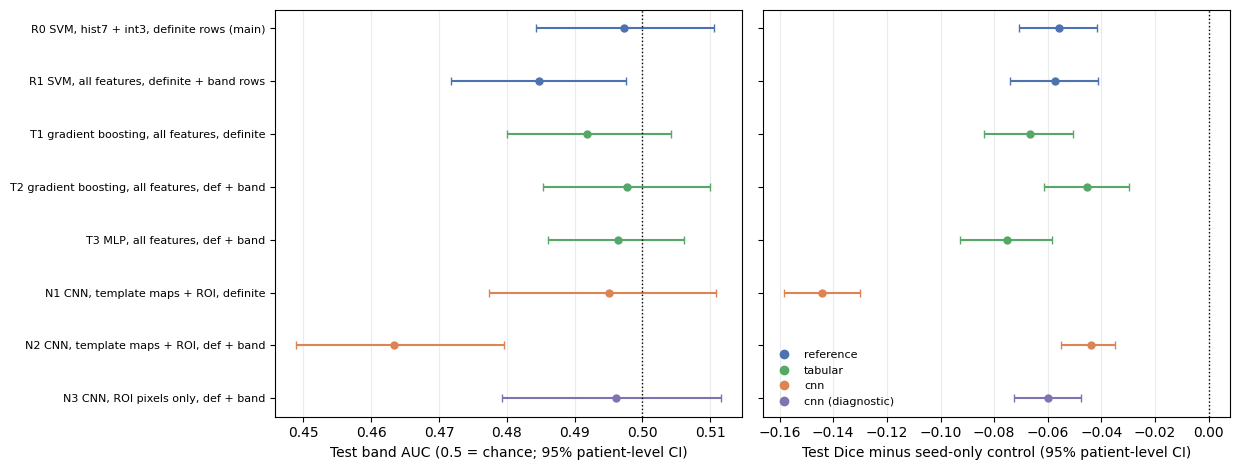

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), sharey=True)
col = {'reference': '#4C72B0', 'tabular': '#55A868', 'cnn': '#DD8452', 'cnn (diagnostic)': '#8172B2'}
ys = np.arange(len(tab))[::-1]
for y, (_, r) in zip(ys, tab.iterrows()):
    axes[0].errorbar(r['test_band_auc'], y, xerr=[[r['test_band_auc'] - r['test_band_lo']], [r['test_band_hi'] - r['test_band_auc']]], fmt='o', color=col[r['family']], capsize=3, ms=5)
    axes[1].errorbar(r['d_vs_baseline'], y, xerr=[[r['d_vs_baseline'] - r['d_vs_baseline_lo']], [r['d_vs_baseline_hi'] - r['d_vs_baseline']]], fmt='o', color=col[r['family']], capsize=3, ms=5)
axes[0].axvline(0.5, color='k', lw=1, ls=':'); axes[0].set_xlabel("Test band AUC (0.5 = chance; 95% patient-level CI)")
axes[1].axvline(0, color='k', lw=1, ls=':'); axes[1].set_xlabel("Test Dice minus seed-only control (95% patient-level CI)")
axes[0].set_yticks(ys); axes[0].set_yticklabels(tab['run'], fontsize=8)
for k, v in col.items(): axes[1].plot([], [], 'o', color=v, label=k)
axes[1].legend(fontsize=8, loc='lower left', frameon=False)
for a in axes: a.grid(axis='x', alpha=0.25)
plt.tight_layout(); plt.savefig(os.path.join(FIGURES_DIR, "fig_nb7_classifier_study.png"), dpi=150); plt.show()

In [ ]:
def verify_nb7():
    ids_sets = [set(RESULTS_RUN[r][0]['image_id']) for r in RUN_NAMES]
    touched = set().union(*[set(RESULTS_RUN[r][1]['fit_touched']) for r in RUN_NAMES])
    checks = {
        "all 8 declared runs are reported"                          : len(RESULTS_RUN) == 8 and list(RESULTS_RUN) == RUN_NAMES,
        "every run scored the identical test images"                : all(s == ids_sets[0] for s in ids_sets),
        "those images are the whole test split"                     : ids_sets[0] == test_ids,
        "no test image reached any fitting routine"                 : bool(touched) and not (touched & test_ids) and touched <= (train_ids | val_ids),
        "CNN training and epoch choice used train / validation only": not (set(CNN_X) & test_ids) and set(CNN_X) <= (train_ids | val_ids),
        "baseline is one set of numbers (seed-only control)"        : set(BASE['image_id']) == test_ids,
        "evaluation seeds never use the whole mask"                 : np.mean([(preprocessed_results[i]['trimap_eval'] == 255).sum() < (GT[i] > 127).sum() for i in EVAL_TEST]) >= 0.95,
        "K and Layer 5 variant are those frozen in Notebooks 3-4"   : all(RESULTS_RUN[r][1]['K'] == FINAL_K and RESULTS_RUN[r][1]['layer5'] == L5_MAIN for r in RUN_NAMES),
        "P0 preprocessing reproduces the stored ROIs"               : max(chk) < 1e-3,
        "metrics finite for >= 99% of images in every run"          : all(RESULTS_RUN[r][0]['dice'].notna().mean() >= 0.99 for r in RUN_NAMES),
        "validation and test band AUC finite for every run"         : all(np.isfinite(RESULTS_RUN[r][1][k]) for r in RUN_NAMES for k in ('val_band_auc', 'test_band_auc')),
        "outputs saved"                                             : all(os.path.exists(p) for p in [os.path.join(RESULTS_DIR, f) for f in
                                                                       ("table5_classifier_study.csv", "tableS2_classifier_study_full.csv", "classifier_study_paired_ci.csv")] + [os.path.join(FIGURES_DIR, "fig_nb7_classifier_study.png")]),
    }
    print("=" * 60); print("NOTEBOOK 7 VERIFICATION"); print("=" * 60); ok = True
    for k, v in checks.items(): print(f"  {'OK  ' if bool(v) else 'FAIL'}  {k}"); ok = ok and bool(v)
    print("=" * 60); print("Classifier study complete." if ok else "Review failures."); return ok
verify_nb7()


NOTEBOOK 7 VERIFICATION
  OK    all 8 declared runs are reported
  OK    every run scored the identical test images
  OK    those images are the whole test split
  OK    no test image reached any fitting routine
  OK    CNN training and epoch choice used train / validation only
  OK    baseline is one set of numbers (seed-only control)
  OK    evaluation seeds never use the whole mask
  OK    K and Layer 5 variant are those frozen in Notebooks 3-4
  OK    P0 preprocessing reproduces the stored ROIs
  OK    metrics finite for >= 99% of images in every run
  OK    validation and test band AUC finite for every run
  OK    outputs saved
Classifier study complete.


True